## 📦 Fetching LaDe-D (Cainiao-AI) dataset from Hugging Face

This notebook loads and visualizes the Hugging Face dataset **Cainiao-AI/LaDe-D**. It auto-detects schema and produces reasonable plots (labels, numerics, geo, images). For more informaiton about this dataset, check: [LaDe: The First Comprehensive Last-mile Delivery Dataset from Industry](https://github.com/wenhaomin/LaDe)

<img src="Last_mile_delivery.png" alt="Last mile delivery" width="500">

For more information about last-mile delivery, read: [Last-Mile Delivery: Definition and Trends](https://alaakhamis.medium.com/last-mile-delivery-e369dcb8d5cf)

### Install (first run only)
Uncomment if needed:
```python
# %pip install -U datasets pillow pandas matplotlib ipywidgets jupyterlab jupyter hf_xet huggingface_hub
```

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset, ClassLabel, Image, Value, Features
from PIL import Image as PILImage
from tqdm.auto import tqdm
import folium
from folium.plugins import MarkerCluster
from IPython.display import display


%matplotlib inline
plt.rcParams['figure.figsize'] = (7,4)
plt.rcParams['figure.dpi'] = 120

DATASET_PATH = 'Cainiao-AI/LaDe-D'
SPLIT = 'train'

### Load dataset


In [2]:
# Manual tqdm wrapper for load_dataset
with tqdm(total=1, desc=f"Loading dataset {DATASET_PATH}") as pbar:
    ds = load_dataset(DATASET_PATH)
    pbar.update(1)   # mark as done when load_dataset finishes

print(ds)

available_splits = list(ds.keys())
print('Available splits:', available_splits)

if SPLIT not in ds:
    SPLIT = available_splits[0]
print('Using split:', SPLIT)

dset = ds[SPLIT]
print('Rows:', len(dset))
print('Features:', dset.features)

Loading dataset Cainiao-AI/LaDe-D:   0%|          | 0/1 [00:00<?, ?it/s]

DatasetDict({
    delivery_cq: Dataset({
        features: ['order_id', 'region_id', 'city', 'courier_id', 'lng', 'lat', 'aoi_id', 'aoi_type', 'accept_time', 'accept_gps_time', 'accept_gps_lng', 'accept_gps_lat', 'delivery_time', 'delivery_gps_time', 'delivery_gps_lng', 'delivery_gps_lat', 'ds'],
        num_rows: 931351
    })
    delivery_hz: Dataset({
        features: ['order_id', 'region_id', 'city', 'courier_id', 'lng', 'lat', 'aoi_id', 'aoi_type', 'accept_time', 'accept_gps_time', 'accept_gps_lng', 'accept_gps_lat', 'delivery_time', 'delivery_gps_time', 'delivery_gps_lng', 'delivery_gps_lat', 'ds'],
        num_rows: 1861600
    })
    delivery_jl: Dataset({
        features: ['order_id', 'region_id', 'city', 'courier_id', 'lng', 'lat', 'aoi_id', 'aoi_type', 'accept_time', 'accept_gps_time', 'accept_gps_lng', 'accept_gps_lat', 'delivery_time', 'delivery_gps_time', 'delivery_gps_lng', 'delivery_gps_lat', 'ds'],
        num_rows: 31415
    })
    delivery_sh: Dataset({
        fea

### Preview rows


In [3]:
preview = dset.select(range(min(5, len(dset))))
try:
    display(preview.to_pandas())
except Exception as e:
    print('Could not render pandas preview:', e)
    print(preview)

,order_id,region_id,city,courier_id,lng,lat,aoi_id,aoi_type,accept_time,accept_gps_time,accept_gps_lng,accept_gps_lat,delivery_time,delivery_gps_time,delivery_gps_lng,delivery_gps_lat,ds
0,2031782,10,Chongqing,73,108.71571,30.90228,50,14,10-22 10:26:00,10-22 10:26:00,108.71826,30.95587,10-22 17:04:00,10-22 17:04:00,108.66361,30.96702,1022
1,4285071,10,Chongqing,3605,108.71639,30.90269,50,14,09-07 10:13:00,09-07 10:13:00,108.71791,30.95635,09-09 15:44:00,09-09 15:44:00,108.71644,30.90266,907
2,4056800,10,Chongqing,3605,108.71645,30.90259,50,14,06-26 09:49:00,06-26 09:49:00,108.71798,30.95635,06-27 16:03:00,06-27 16:03:00,108.71647,30.90251,626
3,3589481,10,Chongqing,3605,108.71650,30.90347,50,14,09-11 11:01:00,09-11 11:01:00,108.71823,30.95596,09-13 17:14:00,09-13 17:14:00,108.71650,30.90341,911
4,2752329,10,Chongqing,3605,108.71608,30.90409,50,14,10-01 09:52:00,10-01 09:52:00,108.71820,30.95598,10-01 18:30:00,10-01 18:30:00,108.71413,30.90397,1001


### Inspect features & categorize columns

In [4]:
features: Features = dset.features
image_cols, label_cols, numeric_cols, text_cols = [], [], [], []
lat_col, lon_col = None, None
for name, feat in features.items():
    if isinstance(feat, Image):
        image_cols.append(name)
    elif isinstance(feat, ClassLabel):
        label_cols.append(name)
    elif isinstance(feat, Value):
        if feat.dtype in ('int32','int64','float32','float64'):
            numeric_cols.append(name)
        elif feat.dtype == 'string':
            text_cols.append(name)
    if name.lower() in ('lat','latitude','y'):
        lat_col = name
    if name.lower() in ('lon','lng','longitude','x'):
        lon_col = name
print('image_cols:', image_cols)
print('label_cols:', label_cols)
print('numeric_cols:', numeric_cols)
print('text_cols:', text_cols)
print('lat, lon:', lat_col, lon_col)

image_cols: []
label_cols: []
numeric_cols: ['order_id', 'region_id', 'courier_id', 'lng', 'lat', 'aoi_id', 'aoi_type', 'accept_gps_lng', 'accept_gps_lat', 'delivery_gps_lng', 'delivery_gps_lat', 'ds']
text_cols: ['city', 'accept_time', 'accept_gps_time', 'delivery_time', 'delivery_gps_time']
lat, lon: lat lng


### Numeric histograms

,order_id,region_id,courier_id,aoi_id,aoi_type,accept_gps_lng,accept_gps_lat,delivery_gps_lng,delivery_gps_lat,ds
count,2.000000e+04,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,2.249996e+06,12.499300,2030.694750,18826.618700,8.561850,107.034490,30.007000,107.023956,30.016437,808.959350
std,1.303619e+06,2.220821,1355.007058,17271.294811,6.486053,0.944758,0.534729,1.612459,0.643770,190.208441
min,1.070000e+02,10.000000,10.000000,9.000000,0.000000,106.393410,29.604010,0.000040,0.000000,501.000000
25%,1.121372e+06,11.000000,853.000000,6971.000000,1.000000,106.393840,29.604150,106.425140,29.626950,619.000000
50%,2.253296e+06,11.000000,1975.000000,8510.000000,14.000000,106.669840,29.795650,106.619230,29.821785,824.000000
75%,3.373802e+06,15.000000,3377.000000,31858.000000,14.000000,106.669990,29.795880,106.793175,29.833130,1013.000000
max,4.514528e+06,15.000000,4539.000000,60104.000000,15.000000,108.722690,30.957290,113.953940,31.420680,1031.000000


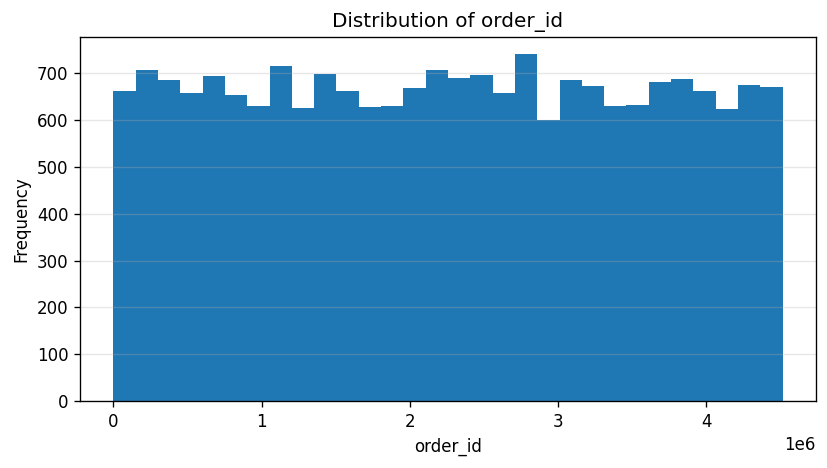

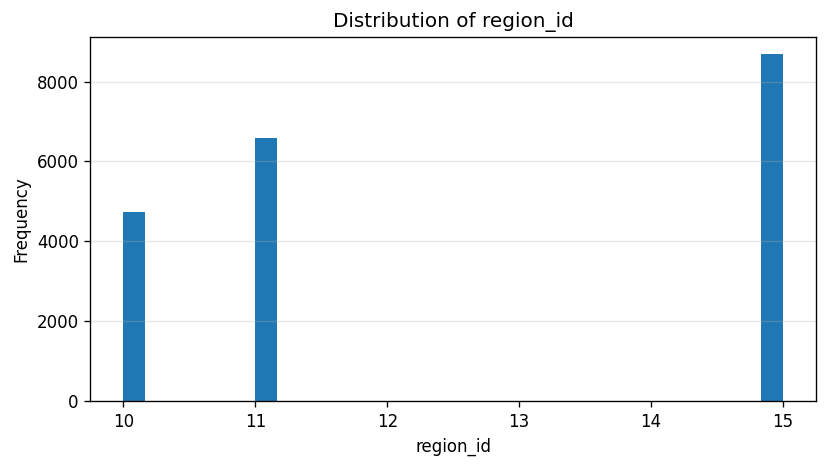

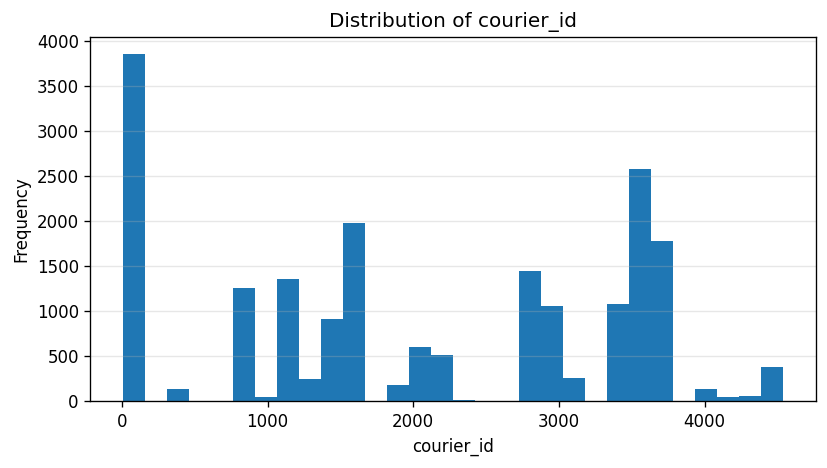

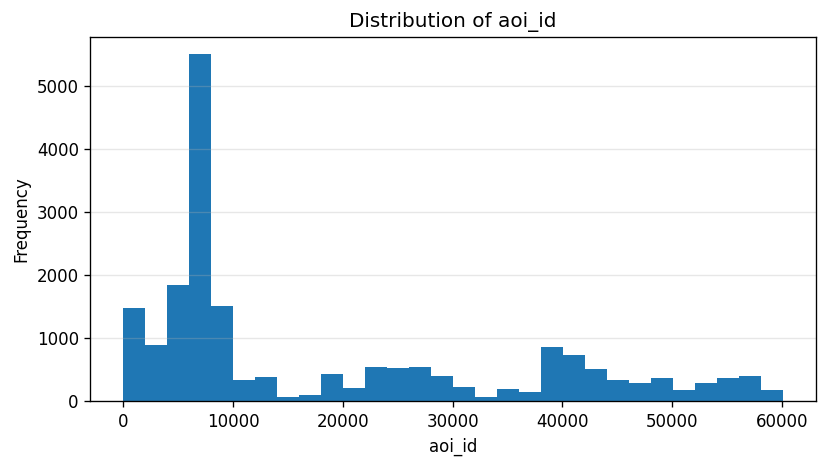

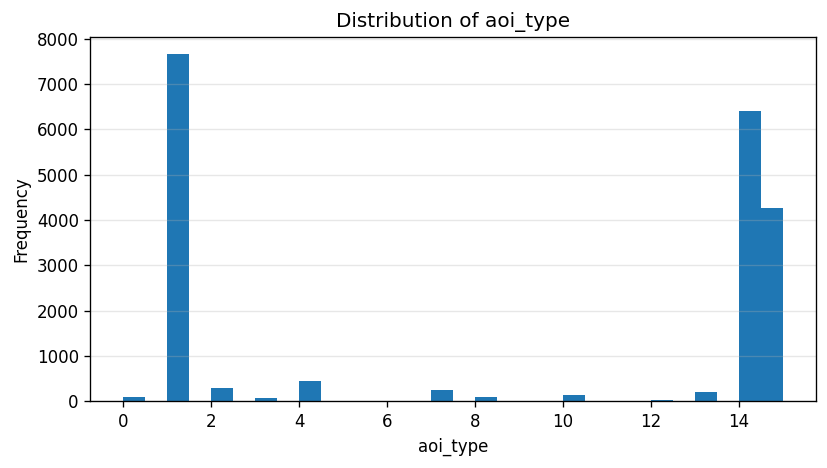

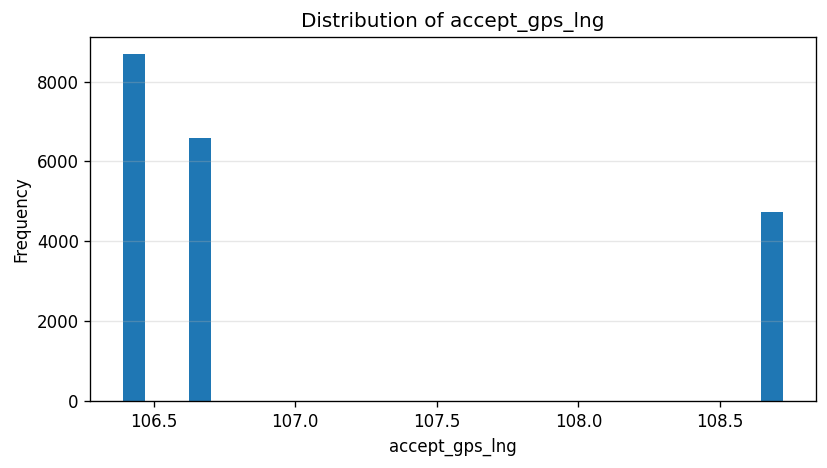

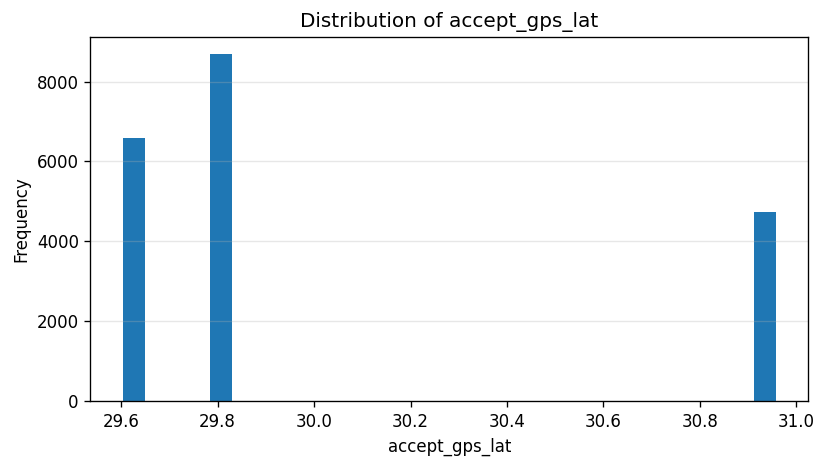

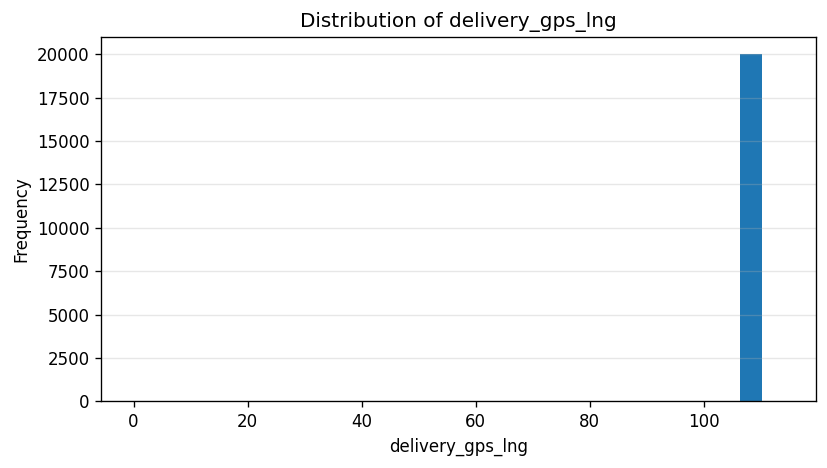

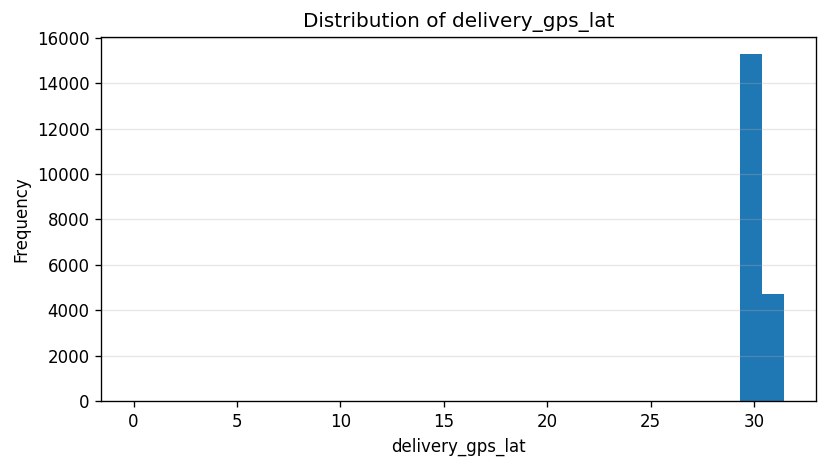

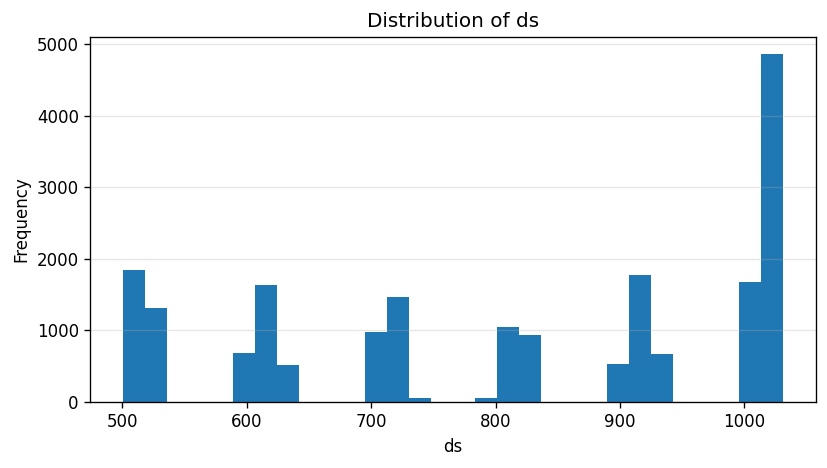

In [5]:
num_cols = [c for c in numeric_cols if c not in (lat_col, lon_col)]
if num_cols:
    df_num = dset.select(range(min(20000, len(dset)))).to_pandas()[num_cols]
    display(df_num.describe())
    for col in num_cols:
        plt.figure()
        plt.hist(df_num[col].dropna(), bins=30)
        plt.title(f'Distribution of {col}')
        plt.xlabel(col); plt.ylabel('Frequency')
        plt.grid(True, axis='y', alpha=0.3)
        plt.tight_layout(); plt.show()
else:
    print('No numeric columns found (excluding lat/lon).')

### Geo scatter

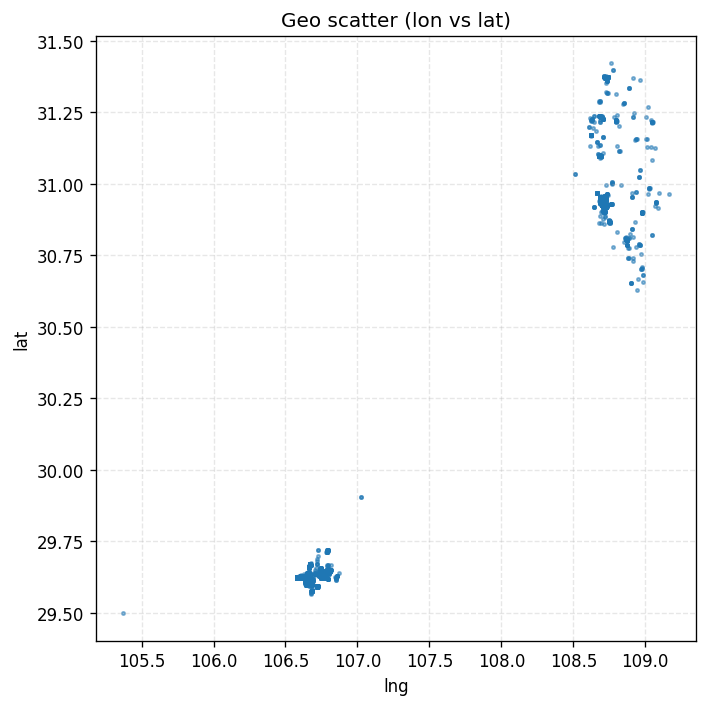

In [6]:
if lat_col and lon_col and lat_col in dset.column_names and lon_col in dset.column_names:
    df_geo = dset.select(range(min(10000, len(dset)))).to_pandas()[[lat_col, lon_col]].dropna()
    df_geo = df_geo[(df_geo[lat_col].between(-90,90)) & (df_geo[lon_col].between(-180,180))]
    plt.figure(figsize=(6,6))
    plt.scatter(df_geo[lon_col], df_geo[lat_col], s=4, alpha=0.5)
    plt.title('Geo scatter (lon vs lat)')
    plt.xlabel(lon_col); plt.ylabel(lat_col)
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout(); plt.show()
else:
    print('No (lat, lon) columns detected.')

In [7]:
# ---- Config ----
# Limit number of points for interactivity (increase if you want)
N_POINTS = 5000

# Columns available in your dataset:
# ['order_id', 'region_id', 'city', 'courier_id', 'lng', 'lat', 'aoi_id', 'aoi_type',
#  'accept_time', 'accept_gps_time', 'accept_gps_lng', 'accept_gps_lat',
#  'delivery_time', 'delivery_gps_time', 'delivery_gps_lng', 'delivery_gps_lat', 'ds']

# ---- Build a compact DataFrame for mapping ----
cols = ['order_id','courier_id','city','lng','lat',
        'accept_gps_lng','accept_gps_lat','accept_time','accept_gps_time',
        'delivery_gps_lng','delivery_gps_lat','delivery_time','delivery_gps_time']

available = [c for c in cols if c in dset.column_names]
df = dset.select(range(min(N_POINTS, len(dset)))).to_pandas()[available].copy()

# Clean main coordinates
df = df.dropna(subset=['lat','lng'])
df = df[df['lat'].between(-90, 90) & df['lng'].between(-180, 180)]

# Center the map on mean location (fallback to [0,0] if empty)
center = [df['lat'].mean() if not df.empty else 0.0,
          df['lng'].mean() if not df.empty else 0.0]

m = folium.Map(location=center, zoom_start=10, tiles="CartoDB Positron")

# Helper to build a popup HTML safely
def popup_html(row):
    def fmt(x): 
        return "" if pd.isna(x) else str(x)
    return folium.IFrame(
        html=(
            f"<b>Order:</b> {fmt(row.get('order_id'))}<br>"
            f"<b>Courier:</b> {fmt(row.get('courier_id'))}<br>"
            f"<b>City:</b> {fmt(row.get('city'))}<br>"
            f"<b>Accept time:</b> {fmt(row.get('accept_time'))} ({fmt(row.get('accept_gps_time'))})<br>"
            f"<b>Delivery time:</b> {fmt(row.get('delivery_time'))} ({fmt(row.get('delivery_gps_time'))})"
        ),
        width=260, height=120
    )

# ---- Layer 1: main lat/lng points ----
cluster_main = MarkerCluster(name="Main (lat/lng)").add_to(m)
for _, row in df.iterrows():
    folium.CircleMarker(
        location=[row['lat'], row['lng']],
        radius=3,
        weight=1,
        fill=True,
        fill_opacity=0.7,
        popup=folium.Popup(popup_html(row))
    ).add_to(cluster_main)

# ---- Optional Layer 2: accept GPS points ----
if {'accept_gps_lat','accept_gps_lng'}.issubset(df.columns):
    df_acc = df.dropna(subset=['accept_gps_lat','accept_gps_lng']).copy()
    df_acc = df_acc[df_acc['accept_gps_lat'].between(-90,90) & df_acc['accept_gps_lng'].between(-180,180)]
    if not df_acc.empty:
        cluster_acc = MarkerCluster(name="Accept GPS").add_to(m)
        for _, row in df_acc.iterrows():
            folium.CircleMarker(
                location=[row['accept_gps_lat'], row['accept_gps_lng']],
                radius=3,
                color="green",
                weight=1,
                fill=True,
                fill_opacity=0.6,
                popup=folium.Popup(popup_html(row))
            ).add_to(cluster_acc)

# ---- Optional Layer 3: delivery GPS points ----
if {'delivery_gps_lat','delivery_gps_lng'}.issubset(df.columns):
    df_del = df.dropna(subset=['delivery_gps_lat','delivery_gps_lng']).copy()
    df_del = df_del[df_del['delivery_gps_lat'].between(-90,90) & df_del['delivery_gps_lng'].between(-180,180)]
    if not df_del.empty:
        cluster_del = MarkerCluster(name="Delivery GPS").add_to(m)
        for _, row in df_del.iterrows():
            folium.CircleMarker(
                location=[row['delivery_gps_lat'], row['delivery_gps_lng']],
                radius=3,
                color="red",
                weight=1,
                fill=True,
                fill_opacity=0.6,
                popup=folium.Popup(popup_html(row))
            ).add_to(cluster_del)

# Layer control to toggle groups
folium.LayerControl().add_to(m)

# Display in notebook (and save to HTML as a robust fallback)
from IPython.display import display
display(m)

# m.save("lade_d_map.html")
# print("Saved interactive map to lade_d_map.html")

### Save small CSV sample

In [9]:
out_csv = 'lade_d_sample.csv'
sample = dset.select(range(min(1000, len(dset))))
try:
    df = sample.to_pandas(); df.to_csv(out_csv, index=False)
    print('Saved:', out_csv)
except Exception as e:
    print('CSV save error:', e)

Saved: lade_d_sample.csv
